In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import affine_transform

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

In [2]:
def rotate_voxel_zyz(voxels, omega, theta, phi, order=1):
    """
    Rotate a 3D voxel array using ZYZ Euler angles.
    order : Interpolation order (0=nearest, 1=linear, etc.) for affine_transform.
    """
    # Compute rotation matrix
    Rz1 = transforms.rotate_z(omega)
    Ry = transforms.rotate_y(theta)
    Rz2 = transforms.rotate_z(phi)
    R = Rz1 @ Ry @ Rz2

    # Center of the volume
    center = np.array(voxels.shape) / 2.0

    # Affine transform expects the inverse rotation
    R_inv = np.linalg.inv(R)

    # Compute offset so rotation is about the center
    offset = center - R_inv @ center

    # Apply affine transform
    rotated = affine_transform(
        voxels,
        R_inv,
        offset=offset,
        order=order,
        mode='constant',
        cval=0.0
    )
    return rotated


def points_to_voxel_index(p, L):
    """
    converts points (x,y,z) in [-1,1]^3 to voxel indices in [0, L-1]^3
    input: p is 3 X n_points array
    """

    p_norm = (p + 1) / 2 * (L-1)
    v_idx = np.floor(p_norm.T).astype('int')

    return v_idx


def fill_voxel_array(v_idx, L, value=1):
    """fill voxel array at specified index with value"""

    ### figure out best conventions, currently:
    ### * UPDATE THIS
    ### - Cartesian x --> Numpy z (axis=0)
    ### - Cartesian y --> Numpy y (axis=1)
    ### - Cartesian z --> Numpy x (axis=2)

    f = np.zeros((L,L,L))

    vx = v_idx[:, 0]
    vy = v_idx[:, 1]
    vz = v_idx[:, 2]

    f[vx, -vz, vy] = value
    
    return f


def generate_voxel_array_from_points(p, L, value=1):
    
    v_idx = points_to_voxel_index(p, L)
    f = fill_voxel_array(v_idx, L, value)

    return f

In [3]:
# p = np.array([[0, -0.33, 0.33], [0, 0, -0.33], [0, 0.33, 0.33]]).T

# # p = np.array([[0, -0.33, 0.33], [0, 0, -0.33], [0, 0.33, 0.33], [-0.4, 0.4, -0.4]]).T
# # p = np.array([0, 0, 0.5]).reshape(3,1)

# ### what conventions / axes / order to use here?
# omega = np.deg2rad(0)
# theta = np.deg2rad(180)
# phi = np.deg2rad(0)

# R1 = transforms.rotate_z(omega)
# R2 = transforms.rotate_y(theta)
# R3 = transforms.rotate_z(phi)
# R = R1 @ R3 @ R2

# ### check the rotation order
# q = R @ p

# L = 49
# sigma = 2

# f = generate_voxel_array_from_points(p, L)
# g = generate_voxel_array_from_points(q, L)
# z = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

# F = utils.signal_convolution(f, z)
# G = utils.signal_convolution(g, z)

# F = signals.Signal(F, d=3).preprocess_signals()
# G = signals.Signal(G, d=3).preprocess_signals()

# print('\t original')
# plots.orthogonal_2D_projection_plot(F[0])
# print('\t rotated')
# plots.orthogonal_2D_projection_plot(G[0])

	 original


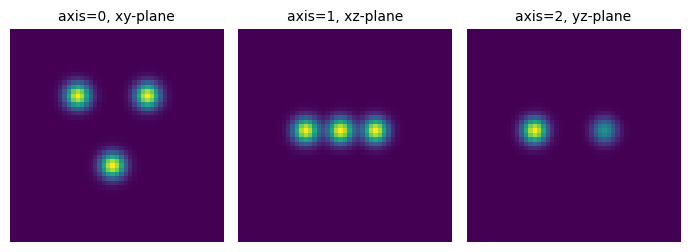

	 rotated


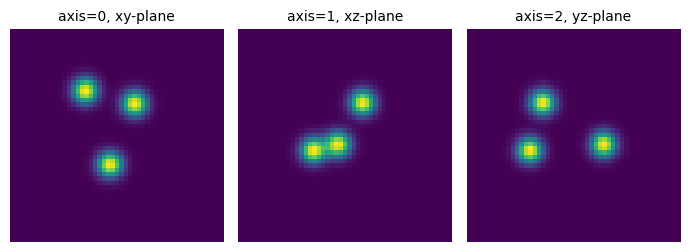

In [39]:
L = 49
sigma = 2

omega = -np.deg2rad(15)
theta = -np.deg2rad(45)
phi = -np.deg2rad(0)

F = utils.generate_3d_triangle_gaussian_shape(L, sigma)
G = rotate_voxel_zyz(F, omega, theta, phi, order=1)

F = signals.Signal(F, d=3).preprocess_signals()
G = signals.Signal(G, d=3).preprocess_signals()

print('\t original')
plots.orthogonal_2D_projection_plot(F[0])
print('\t rotated')
plots.orthogonal_2D_projection_plot(G[0])

In [40]:
U = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()[0]
V = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()[0]

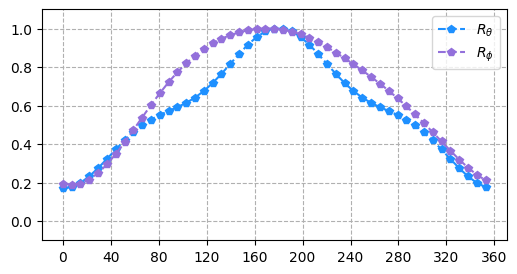



  min_phi:  7.346938775510203
min_theta:  0.0


In [41]:
### Test rotations in either theta or phi individually by shifting tensor

n_phi, n_points, n_theta = U.shape

thetas = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

dists_sw_theta = np.zeros(n_theta)
dists_sw_phi = np.zeros(n_phi)

for theta_idx in range(n_theta):
    V_theta = transforms.translate_3d(V, 0, 0, theta_idx)
    dists_sw_theta[theta_idx] = np.mean((U - V_theta)**2)

for phi_idx in range(n_phi):
    V_phi = transforms.translate_3d(V, phi_idx, 0, 0)
    dists_sw_phi[phi_idx] = np.mean((U - V_phi)**2)


dists_sw_theta = dists_sw_theta / np.amax(dists_sw_theta)
dists_sw_phi = dists_sw_phi / np.amax(dists_sw_phi)


plt.figure(figsize=(6,3))
plt.plot(np.rad2deg(thetas), dists_sw_theta, 'p--', color='dodgerblue', label=r'$R_\theta$')
plt.plot(np.rad2deg(phis), dists_sw_phi, 'p--', color='mediumpurple', label=r'$R_\phi$')
plt.grid(which='major', linestyle='--')
plt.xticks(np.arange(0, 361, 40))
plt.ylim(-0.1, 1.1)
plt.legend()
plt.show()


print('\n')
print('  min_phi: ', np.rad2deg(phis[np.argmin(dists_sw_phi)]))
print('min_theta: ', np.rad2deg(phis[np.argmin(dists_sw_theta)]))

In [42]:
### Loop through rotations of phi for each rotation of theta

n_phi, n_points, n_theta = U.shape
thetas = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

dists_sw_theta_phi = np.zeros((n_theta, n_phi))

t = time.time()

for theta_idx in range(n_theta):
    for phi_idx in range(n_phi):
        V_theta_phi = transforms.translate_3d(V, phi_idx, 0, theta_idx)
        dists_sw_theta_phi[theta_idx, phi_idx] = np.mean((U - V_theta_phi)**2)

print('rotation distance time: ', time.time() - t)

rotation distance time:  0.8293149471282959


In [43]:
dists_sw_theta_phi = dists_sw_theta_phi / np.amax(dists_sw_theta_phi)

min_theta, min_phi = np.round(np.rad2deg(distances.return_min_angles(dists_sw_theta_phi, thetas, phis)), 2)

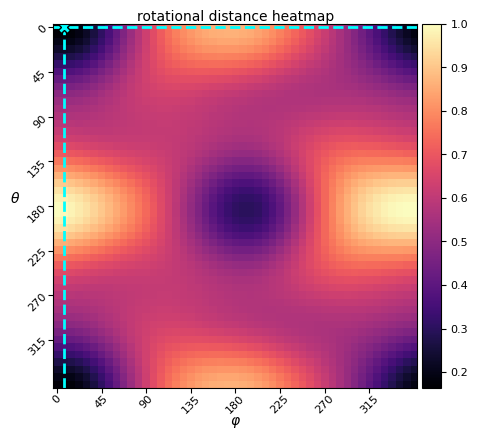



min_theta =  0.0
  min_phi =  7.35


In [44]:
plots.rotational_distance_heatmap(dists_sw_theta_phi)
print('\n')
print('min_theta = ', min_theta)
print('  min_phi = ', min_phi)

In [45]:
### Next try fast rotations with 2D DFT
### axes are flipped compared to previous, is it the indexing of slice?
### should I add the conjugation? transpose at end?

n_phi, n_points, n_theta = U.shape
thetas = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

C = np.zeros(U.shape)

t = time.time()

U_norm = np.linalg.norm(U)**2
V_norm = np.linalg.norm(V)**2

for s in range(n_points):
    
    U_slice = U[:, s, :]
    V_slice = V[:, s, :]
    
    C[:, s, :] =  np.fft.ifft2(np.fft.fft2(U_slice) * np.conj(np.fft.fft2(V_slice))).real
    # C = C * np.sin(thetas)[:, np.newaxis]
    # C[:, s, :] =  np.fft.ifft2(np.fft.fft2(U_slice) * np.fft.fft2(V_slice)).real

dists_sw_theta_phi = U_norm + V_norm - 2*np.sum(C, axis=1)

print('rotation distance time: ', time.time() - t)

rotation distance time:  0.011136293411254883


In [46]:
dists_sw_theta_phi = dists_sw_theta_phi / np.amax(dists_sw_theta_phi)

min_theta, min_phi = np.round(np.rad2deg(distances.return_min_angles(dists_sw_theta_phi, thetas, phis)), 2)

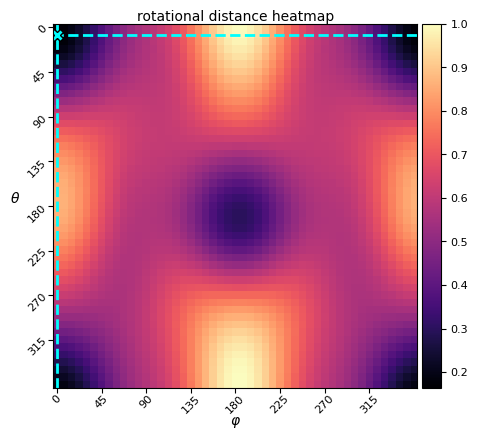



min_theta =  7.35
  min_phi =  0.0


In [47]:
plots.rotational_distance_heatmap(dists_sw_theta_phi)
print('\n')
print('min_theta = ', min_theta)
print('  min_phi = ', min_phi)

In [48]:
np.rad2deg(thetas)

array([  0.        ,   7.34693878,  14.69387755,  22.04081633,
        29.3877551 ,  36.73469388,  44.08163265,  51.42857143,
        58.7755102 ,  66.12244898,  73.46938776,  80.81632653,
        88.16326531,  95.51020408, 102.85714286, 110.20408163,
       117.55102041, 124.89795918, 132.24489796, 139.59183673,
       146.93877551, 154.28571429, 161.63265306, 168.97959184,
       176.32653061, 183.67346939, 191.02040816, 198.36734694,
       205.71428571, 213.06122449, 220.40816327, 227.75510204,
       235.10204082, 242.44897959, 249.79591837, 257.14285714,
       264.48979592, 271.83673469, 279.18367347, 286.53061224,
       293.87755102, 301.2244898 , 308.57142857, 315.91836735,
       323.26530612, 330.6122449 , 337.95918367, 345.30612245,
       352.65306122])

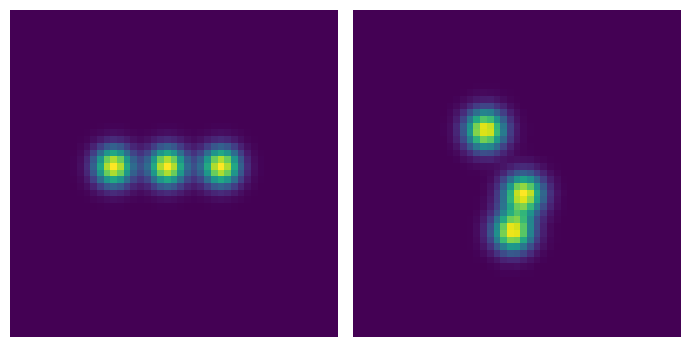

In [54]:
### Then compute the rotation for omega
### need to rotate G by theta, phi first, right?
### then align by in-plane rotation of the projection

# G_theta_phi = rotate_voxel_zyz(G[0], 0, 0, 0, order=1)
G_theta_phi = rotate_voxel_zyz(G[0], 0, -min_theta, -min_phi, order=1)

### confirm which axis to use for z-axis projection
F2d = np.sum(F[0], axis=1)
G2d = np.sum(G_theta_phi, axis=1)

plots.two_imshow(F2d, G2d)

In [55]:
omega = np.linspace(0, 2*np.pi, L, endpoint=False)

t = time.time()
U = transforms.Transform(F2d, d=2, apply_ramp=False).inverse_cdf_transform()[0]
V = transforms.Transform(G2d, d=2, apply_ramp=False).inverse_cdf_transform()[0]

d_sw_omega = distances.fast_rotational_distance_2d(U, V)
print('rotational distance time :', time.time() - t)

d_sw_omega = d_sw_omega / np.amax(d_sw_omega)
min_omega = omega[np.argmin(d_sw_omega)]

rotational distance time : 0.0037848949432373047


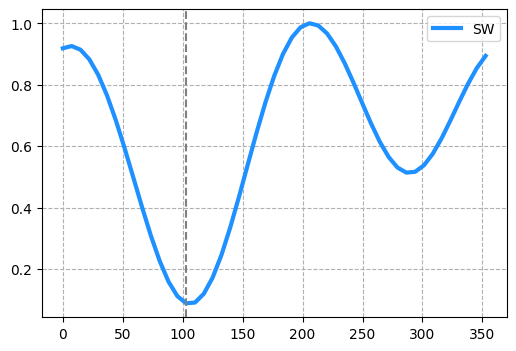

min_omega =  102.85714285714286


In [56]:
### add this to plots

plt.figure(figsize=(6,4))
plt.plot(np.rad2deg(omega), d_sw_omega, linewidth=3, color='dodgerblue', label='SW')
plt.axvline(np.rad2deg(min_omega), linewidth=1.5, linestyle='--', color='grey')
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

print('min_omega = ', np.rad2deg(min_omega))

In [57]:
print(np.rad2deg(omega))

[  0.           7.34693878  14.69387755  22.04081633  29.3877551
  36.73469388  44.08163265  51.42857143  58.7755102   66.12244898
  73.46938776  80.81632653  88.16326531  95.51020408 102.85714286
 110.20408163 117.55102041 124.89795918 132.24489796 139.59183673
 146.93877551 154.28571429 161.63265306 168.97959184 176.32653061
 183.67346939 191.02040816 198.36734694 205.71428571 213.06122449
 220.40816327 227.75510204 235.10204082 242.44897959 249.79591837
 257.14285714 264.48979592 271.83673469 279.18367347 286.53061224
 293.87755102 301.2244898  308.57142857 315.91836735 323.26530612
 330.6122449  337.95918367 345.30612245 352.65306122]


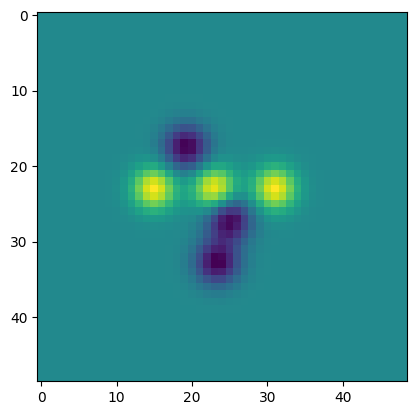

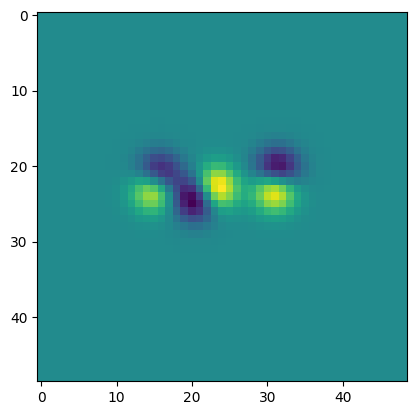

In [58]:
G2d_aligned = utils.rotate_image(G2d, -np.rad2deg(min_omega))
# G2d_aligned = utils.rotate_image(G2d, -180)

plt.imshow(F2d - G2d)
plt.show()
plt.imshow(F2d - G2d_aligned)
plt.show()